# Human Activity Recognition Using Smartphone Sensor Data: PCA and Clustering

**Course:** AAI 501: Introduction to Artificial Intelligence  
**University:** University of San Diego  
**Project:** Final Team Project  
**Team Members:** Francois Lubin, Lernik Avetisyan, Alex Denbaugh

## Project Overview

This notebook investigates patterns in smartphone sensor data using Principal Component Analysis (PCA) and unsupervised clustering techniques. It contributes to the team's Human Activity Recognition project by focusing on dimensionality reduction, K-Means clustering, hierarchical clustering, and the potential contribution of cluster-distance features to activity classification.

The analysis uses the UCI Human Activity Recognition Using Smartphones dataset, containing 10,299 observations, 561 engineered sensor features, and six recorded activities: walking, walking upstairs, walking downstairs, sitting, standing, and laying.

## Research Objectives

1. Examine how PCA reduces feature dimensionality while retaining information about the variation in the sensor data.
2. Investigate whether K-Means identifies meaningful activity groups, particularly moving versus stationary activities.
3. Compare K-Means and hierarchical clustering using consistent evaluation metrics and a common training sample.
4. Evaluate whether the identified K-Means grouping generalizes to previously unseen participants.
5. Determine whether adding cluster-distance features improves six-activity classification performance.

## Methodology

The original dataset's participant-separated training and testing partitions are preserved. Feature standardization and PCA are fitted using training data only, with 90% explained variance retained for the primary analysis. K-Means cluster counts are evaluated from 2 through 10 using training-data silhouette scores. Recorded activity labels are used to evaluate clustering results, not to fit K-Means or select its cluster count.

Ward hierarchical clustering is performed on an activity-stratified sample of 2,000 training observations. Activity labels determine sample composition but are not used as clustering features. K-Means is also fitted on the same sample for comparison.

A focused Logistic Regression experiment compares PCA features alone against PCA features supplemented with distances to K-Means cluster centers. Five-fold participant-aware cross-validation refits preprocessing, PCA, clustering, and classification within each training fold. PCA component counts are selected within each fold using the 90% variance rule, while the previously selected K-Means cluster count remains fixed.

## Notebook Structure

1. **Introduction and Data Loading:** Import libraries, load the dataset, and verify its structure and integrity.
2. **Data Preparation:** Standardize sensor features using training-derived statistics.
3. **Principal Component Analysis:** Analyze explained variance, reduce dimensionality, and visualize activity patterns.
4. **K-Means Clustering:** Evaluate cluster counts, interpret activity composition, and test generalization to held-out participants.
5. **Hierarchical Clustering:** Apply Ward linkage, compare clustering solutions, and visualize the hierarchical structure.
6. **Cluster-Distance Classification:** Evaluate whether K-Means distance features provide additional classification value.
7. **Final Evaluation and Validation:** Consolidate experimental metrics and verify dataset separation and consistency.
8. **Conclusions and Integration:** Summarize findings, limitations, and contributions to the team project.

## Research Scope

This notebook focuses on PCA, clustering, and the evaluation of cluster-distance features. It complements the team's supervised classification and feature-selection notebooks rather than replacing or duplicating their analyses. Classification is included only to evaluate the additional value of cluster-distance features.

## **Section 1:** Introduction and Data Loading

This section introduces the Human Activity Recognition Using Smartphones dataset from the UCI Machine Learning Repository. The analysis begins by importing the required Python libraries and loading the smartphone sensor data. The dataset is then examined to verify its dimensions, features, activity labels, and participant identifiers before proceeding to Principal Component Analysis (PCA) and clustering.

**Step 1.1:** Library Installation and Imports

In [1]:
# Install the required scikit-learn version.
%pip install -q --upgrade scikit-learn==1.8.0

# Standard libraries and dataset loading
import sys
import urllib.request
import zipfile
from pathlib import Path

# Data manipulation and visualization
import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
import sklearn

# Data preparation and dimensionality reduction
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Clustering algorithms
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram

# Model evaluation
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    accuracy_score,
    f1_score,
)

# Classification and participant-aware validation
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    train_test_split,
    StratifiedGroupKFold,
)
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin, clone

# Reproducibility
RANDOM_STATE = 42

# Verify the required scikit-learn version.
assert sklearn.__version__ == "1.8.0", (
    f"Expected scikit-learn 1.8.0, found {sklearn.__version__}. "
    "Restart the runtime and rerun this cell if necessary."
)

print("Required libraries imported successfully.")
print("Random state:", RANDOM_STATE)

print("\nEXECUTION ENVIRONMENT")
print("=" * 40)
print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("matplotlib:", matplotlib.__version__)

print("\nEnvironment verification passed.")

Required libraries imported successfully.
Random state: 42

EXECUTION ENVIRONMENT
Python: 3.13.18
scikit-learn: 1.8.0
NumPy: 2.1.3
pandas: 2.2.3
SciPy: 1.16.3
matplotlib: 3.10.0

Environment verification passed.


**Step 1.2:** Dataset Loading

In [2]:
# Define dataset storage location.
DATA_DIR = Path("/content/uci_har")
DATA_DIR.mkdir(parents=True, exist_ok=True)

DATASET_URL = (
    "https://archive.ics.uci.edu/static/public/240/"
    "human+activity+recognition+using+smartphones.zip"
)

ZIP_PATH = DATA_DIR / "uci_har.zip"

# Download the official UCI HAR dataset.
if not ZIP_PATH.exists():
    urllib.request.urlretrieve(DATASET_URL, ZIP_PATH)

# Extract the outer archive.
with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    archive.extractall(DATA_DIR)

# Locate and extract the inner dataset archive.
inner_zips = list(DATA_DIR.rglob("UCI HAR Dataset.zip"))

if inner_zips:
    with zipfile.ZipFile(inner_zips[0], "r") as archive:
        archive.extractall(DATA_DIR)

# Locate the extracted dataset directory.
dataset_dirs = [
    path for path in DATA_DIR.rglob("UCI HAR Dataset")
    if path.is_dir()
    and (path / "train" / "X_train.txt").is_file()
]

assert len(dataset_dirs) == 1, (
    f"Expected one dataset directory, found {len(dataset_dirs)}."
)

HAR_DIR = dataset_dirs[0]

# Load the original training and testing features.
X_train = pd.read_csv(
    HAR_DIR / "train" / "X_train.txt",
    sep=r"\s+",
    header=None
)

X_test = pd.read_csv(
    HAR_DIR / "test" / "X_test.txt",
    sep=r"\s+",
    header=None
)

# Load activity labels.
y_train = pd.read_csv(
    HAR_DIR / "train" / "y_train.txt",
    header=None
).iloc[:, 0].to_numpy()

y_test = pd.read_csv(
    HAR_DIR / "test" / "y_test.txt",
    header=None
).iloc[:, 0].to_numpy()

# Load participant identifiers.
subject_train = pd.read_csv(
    HAR_DIR / "train" / "subject_train.txt",
    header=None
).iloc[:, 0].to_numpy()

subject_test = pd.read_csv(
    HAR_DIR / "test" / "subject_test.txt",
    header=None
).iloc[:, 0].to_numpy()

# Load feature metadata and activity names.
features = pd.read_csv(
    HAR_DIR / "features.txt",
    sep=r"\s+",
    header=None,
    names=["feature_id", "feature_name"]
)

activities = pd.read_csv(
    HAR_DIR / "activity_labels.txt",
    sep=r"\s+",
    header=None,
    names=["activity_id", "activity_name"]
)

# Validate dataset dimensions and participant separation.
assert X_train.shape == (7352, 561)
assert X_test.shape == (2947, 561)
assert len(y_train) == len(subject_train) == len(X_train)
assert len(y_test) == len(subject_test) == len(X_test)
assert len(features) == 561
assert len(activities) == 6
assert set(subject_train).isdisjoint(set(subject_test))

print("Dataset loaded successfully.")

print("\nDATASET SUMMARY")
print("=" * 45)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Total samples:", len(X_train) + len(X_test))
print("Number of features:", X_train.shape[1])
print("Number of activities:", len(activities))
print("Training participants:", len(np.unique(subject_train)))
print("Testing participants:", len(np.unique(subject_test)))
print("Participant overlap:", len(
    set(subject_train) & set(subject_test)
))

print("\nACTIVITY LABELS")
print(activities.to_string(index=False))

Dataset loaded successfully.

DATASET SUMMARY
Training samples: 7352
Testing samples: 2947
Total samples: 10299
Number of features: 561
Number of activities: 6
Training participants: 21
Testing participants: 9
Participant overlap: 0

ACTIVITY LABELS
 activity_id      activity_name
           1            WALKING
           2   WALKING_UPSTAIRS
           3 WALKING_DOWNSTAIRS
           4            SITTING
           5           STANDING
           6             LAYING


**Results:** The UCI Human Activity Recognition Using Smartphones dataset was successfully loaded with 10,299 observations and 561 engineered sensor features. The original training partition contains 7,352 observations from 21 participants, while the testing partition contains 2,947 observations from nine different participants. All six activity classes were identified, and no participants overlap between the training and testing partitions. This separation supports evaluation on previously unseen individuals.

**Step 1.3:** Dataset Structure and Integrity Verification

In [3]:
# Verify feature dimensions and numeric data.
print("FEATURE MATRIX STRUCTURE")
print("=" * 45)
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Training data type:", X_train.dtypes.unique().tolist())
print("Testing data type:", X_test.dtypes.unique().tolist())

# Check for missing or infinite feature values.
train_values = X_train.to_numpy()
test_values = X_test.to_numpy()

print("\nDATA INTEGRITY")
print("=" * 45)
print("Training missing values:", X_train.isna().sum().sum())
print("Testing missing values:", X_test.isna().sum().sum())
print("Training infinite values:", np.isinf(train_values).sum())
print("Testing infinite values:", np.isinf(test_values).sum())

# Verify activity distributions.
activity_names = dict(
    zip(activities["activity_id"], activities["activity_name"])
)

train_counts = pd.Series(y_train).value_counts().sort_index()
test_counts = pd.Series(y_test).value_counts().sort_index()

activity_summary = pd.DataFrame({
    "Activity": [
        activity_names[i] for i in train_counts.index
    ],
    "Training": train_counts.values,
    "Testing": test_counts.values
})

activity_summary["Total"] = (
    activity_summary["Training"] + activity_summary["Testing"]
)

print("\nACTIVITY DISTRIBUTION")
print("=" * 45)
print(activity_summary.to_string(index=False))

# Verify participant coverage and label consistency.
print("\nPARTICIPANT AND LABEL VERIFICATION")
print("=" * 45)
print("Training participant IDs:",
      sorted(np.unique(subject_train).tolist()))
print("Testing participant IDs:",
      sorted(np.unique(subject_test).tolist()))

assert np.isfinite(train_values).all()
assert np.isfinite(test_values).all()
assert set(np.unique(y_train)) == set(range(1, 7))
assert set(np.unique(y_test)) == set(range(1, 7))
assert len(set(subject_train) & set(subject_test)) == 0

print("\nDataset integrity verification passed.")

FEATURE MATRIX STRUCTURE
Training shape: (7352, 561)
Testing shape: (2947, 561)
Training data type: [dtype('float64')]
Testing data type: [dtype('float64')]

DATA INTEGRITY
Training missing values: 0
Testing missing values: 0
Training infinite values: 0
Testing infinite values: 0

ACTIVITY DISTRIBUTION
          Activity  Training  Testing  Total
           WALKING      1226      496   1722
  WALKING_UPSTAIRS      1073      471   1544
WALKING_DOWNSTAIRS       986      420   1406
           SITTING      1286      491   1777
          STANDING      1374      532   1906
            LAYING      1407      537   1944

PARTICIPANT AND LABEL VERIFICATION
Training participant IDs: [1, 3, 5, 6, 7, 8, 11, 14, 15, 16, 17, 19, 21, 22, 23, 25, 26, 27, 28, 29, 30]
Testing participant IDs: [2, 4, 9, 10, 12, 13, 18, 20, 24]

Dataset integrity verification passed.


**Results:** The dataset integrity checks confirmed that both feature matrices contain 561 numerical features with no missing or infinite values. All six activity classes are represented in the training and testing partitions, with 21 training participants and nine testing participants. The participant identifiers remain completely separated across the two partitions. These results confirm that the dataset is suitable for the planned preprocessing, dimensionality reduction, and clustering analyses.

## **Section 2:** Data Preparation

This section prepares the smartphone sensor features for PCA and clustering. Feature standardization is performed using statistics calculated exclusively from the training partition to prevent information leakage. The same transformation is then applied to the testing partition, preserving the original participant separation.

**Step 2.1:** Feature Standardization

In [4]:
# Initialize the feature standardizer.
scaler = StandardScaler()

# Learn scaling parameters from training data only.
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same transformation to testing data.
X_test_scaled = scaler.transform(X_test)

# Verify transformed dataset dimensions.
assert X_train_scaled.shape == X_train.shape
assert X_test_scaled.shape == X_test.shape

# Verify all standardized values are finite.
assert np.isfinite(X_train_scaled).all()
assert np.isfinite(X_test_scaled).all()

# Check standardized training feature statistics.
train_means = X_train_scaled.mean(axis=0)
train_stds = X_train_scaled.std(axis=0)

constant_features = np.sum(scaler.var_ == 0)
nonconstant_features = scaler.var_ > 0

print("FEATURE STANDARDIZATION")
print("=" * 45)
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)
print("Scaler fitted on: Training data only")

print("\nTRAINING FEATURE STATISTICS")
print("=" * 45)
print("Maximum absolute feature mean:",
      round(np.max(np.abs(train_means)), 10))
print("Mean standard deviation (nonconstant features):",
      round(np.mean(train_stds[nonconstant_features]), 6))
print("Constant features:", constant_features)

print("\nDATA VALIDATION")
print("=" * 45)
print("Training values finite:",
      np.isfinite(X_train_scaled).all())
print("Testing values finite:",
      np.isfinite(X_test_scaled).all())
print("Participant separation preserved:",
      set(subject_train).isdisjoint(set(subject_test)))

print("\nFeature standardization completed successfully.")

FEATURE STANDARDIZATION
Training shape: (7352, 561)
Testing shape: (2947, 561)
Scaler fitted on: Training data only

TRAINING FEATURE STATISTICS
Maximum absolute feature mean: 0.0
Mean standard deviation (nonconstant features): 1.0
Constant features: 0

DATA VALIDATION
Training values finite: True
Testing values finite: True
Participant separation preserved: True

Feature standardization completed successfully.


**Results:** Feature standardization was completed successfully using statistics calculated exclusively from the training partition. The standardized training features have approximately zero mean and unit standard deviation, with no constant features or nonfinite values. Both feature matrices retain their original dimensions, and participant separation is preserved. The prepared data can now be used for PCA and clustering without introducing information from the testing partition during standardization.

**Step 2.2:** Verify Standardized Feature Distributions

In [5]:
# Summarize standardized values across all features.
summary = pd.DataFrame({
    "Statistic": [
        "Minimum",
        "Maximum",
        "Mean",
        "Standard deviation"
    ],
    "Training": [
        X_train_scaled.min(),
        X_train_scaled.max(),
        X_train_scaled.mean(),
        X_train_scaled.std()
    ],
    "Testing": [
        X_test_scaled.min(),
        X_test_scaled.max(),
        X_test_scaled.mean(),
        X_test_scaled.std()
    ]
})

print("STANDARDIZED FEATURE DISTRIBUTIONS")
print("=" * 50)
print(summary.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

# Confirm training statistics remain approximately standardized.
assert np.allclose(X_train_scaled.mean(axis=0), 0, atol=1e-10)
assert np.allclose(X_train_scaled.std(axis=0), 1, atol=1e-10)

# Confirm the training-derived transformation is reused.
X_test_reconstructed = (
    X_test.to_numpy() - scaler.mean_
) / scaler.scale_

assert np.allclose(X_test_scaled, X_test_reconstructed)

print("\nTraining feature statistics verified.")
print("Testing transformation verified.")
print("Standardized feature distribution checks passed.")

STANDARDIZED FEATURE DISTRIBUTIONS
         Statistic   Training    Testing
           Minimum -24.071521 -12.333262
           Maximum  34.194056  19.429669
              Mean   0.000000  -0.011128
Standard deviation   1.000000   0.928933

Training feature statistics verified.
Testing transformation verified.
Standardized feature distribution checks passed.


**Results:** The standardized training features have an overall mean of approximately zero and a standard deviation of 1.0. The testing features have a mean of -0.011128 and a standard deviation of 0.928933, reflecting differences between the training and testing participants. All verification checks passed, confirming that the training-derived scaling parameters were correctly applied to the testing data without refitting.

## **Section 3:** Principal Component Analysis (PCA)

This section applies Principal Component Analysis (PCA) to examine the dimensional structure of the standardized smartphone sensor features. PCA is fitted exclusively on the training partition to prevent information leakage. The analysis evaluates how much variance is retained by different numbers of principal components and investigates whether the reduced feature space captures meaningful patterns across human activities.

**Step 3.1:** PCA Explained Variance Analysis

In [6]:
# Fit PCA using standardized training features only.
pca_full = PCA(svd_solver="full")
pca_full.fit(X_train_scaled)

# Calculate explained variance statistics.
explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# Determine components needed for selected variance thresholds.
thresholds = [0.80, 0.90, 0.95, 0.99]

variance_summary = pd.DataFrame({
    "Variance retained": [f"{t:.0%}" for t in thresholds],
    "Components required": [
        np.searchsorted(cumulative_variance, t) + 1
        for t in thresholds
    ]
})

print("PCA EXPLAINED VARIANCE ANALYSIS")
print("=" * 50)
print("Original features:", X_train_scaled.shape[1])
print("Total principal components:", len(explained_variance))

print("\nVARIANCE RETENTION THRESHOLDS")
print("=" * 50)
print(variance_summary.to_string(index=False))

print("\nSELECTED COMPONENT COUNTS")
print("=" * 50)

for n in [2, 10, 20, 50, 100, 200]:
    print(
        f"{n:3d} components: "
        f"{cumulative_variance[n - 1]:.4%} variance retained"
    )

# Verify that explained variance ratios are valid.
assert np.all(explained_variance >= 0)
assert np.all(np.diff(cumulative_variance) >= -1e-12)
assert np.isclose(cumulative_variance[-1], 1.0, atol=1e-8)

print("\nPCA explained variance verification passed.")

PCA EXPLAINED VARIANCE ANALYSIS
Original features: 561
Total principal components: 561

VARIANCE RETENTION THRESHOLDS
Variance retained  Components required
              80%                   26
              90%                   63
              95%                  102
              99%                  179

SELECTED COMPONENT COUNTS
  2 components: 57.3619% variance retained
 10 components: 70.8156% variance retained
 20 components: 77.3746% variance retained
 50 components: 87.5184% variance retained
100 components: 94.8915% variance retained
200 components: 99.3636% variance retained

PCA explained variance verification passed.


**Results:** PCA identified substantial redundancy in the 561 standardized sensor features. A total of 26 principal components retained 80% of the variance, 63 retained 90%, 102 retained 95%, and 179 retained 99%. The first two components explained approximately 57.36% of the variance, while 20 components explained 77.37%. These results demonstrate that PCA can substantially reduce feature dimensionality while preserving much of the dataset's variation. The usefulness of the reduced features for activity clustering will be evaluated in subsequent steps.

**Step 3.2:** Visualize PCA Explained Variance

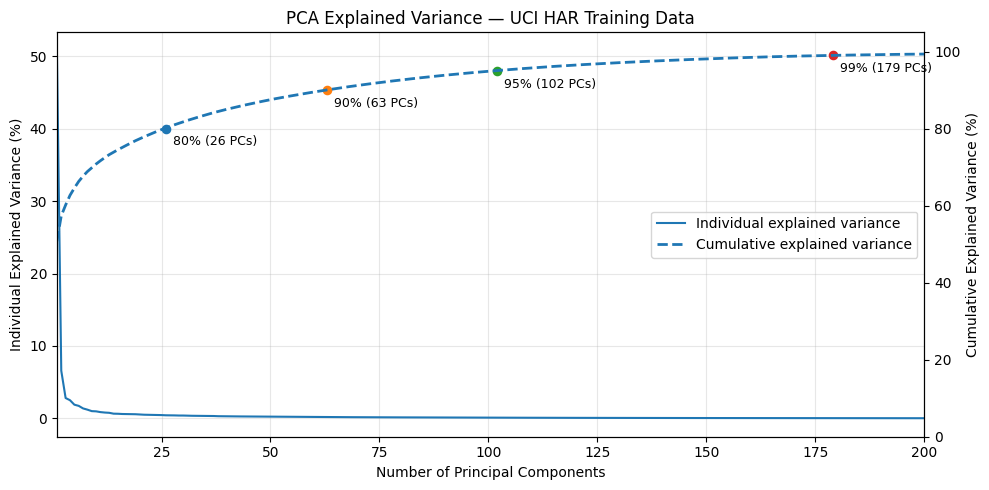

PCA explained variance visualization completed.


In [7]:
# Visualize individual and cumulative explained variance.
component_numbers = np.arange(1, len(explained_variance) + 1)

fig, ax1 = plt.subplots(figsize=(10, 5))

# Individual explained variance.
ax1.plot(
    component_numbers,
    explained_variance * 100,
    label="Individual explained variance",
    linewidth=1.5
)
ax1.set_xlabel("Number of Principal Components")
ax1.set_ylabel("Individual Explained Variance (%)")
ax1.set_xlim(1, 200)
ax1.grid(alpha=0.3)

# Cumulative explained variance.
ax2 = ax1.twinx()
ax2.plot(
    component_numbers,
    cumulative_variance * 100,
    linestyle="--",
    linewidth=2,
    label="Cumulative explained variance"
)
ax2.set_ylabel("Cumulative Explained Variance (%)")
ax2.set_ylim(0, 105)

# Mark important variance thresholds.
for threshold in [80, 90, 95, 99]:
    count = np.searchsorted(
        cumulative_variance,
        threshold / 100
    ) + 1

    ax2.scatter(count, threshold, s=35)
    ax2.annotate(
        f"{threshold}% ({count} PCs)",
        (count, threshold),
        xytext=(5, -12),
        textcoords="offset points",
        fontsize=9
    )

# Combine legend labels from both axes.
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="center right"
)

plt.title("PCA Explained Variance — UCI HAR Training Data")
plt.tight_layout()
plt.show()

print("PCA explained variance visualization completed.")

**Results:** The visualization shows that the first principal components explain a substantial portion of the total variance, while subsequent components contribute progressively smaller amounts. The cumulative variance reaches 80% with 26 components, 90% with 63 components, 95% with 102 components, and 99% with 179 components. The results support using PCA to reduce the dimensionality of the sensor data before clustering, although the effectiveness of the reduced representation must be evaluated separately.

**Step 3.3:** Transform Features Using PCA

In [8]:
# Select the number of components retaining at least 90% variance.
PCA_VARIANCE_THRESHOLD = 0.90

n_components_90 = (
    np.searchsorted(
        cumulative_variance,
        PCA_VARIANCE_THRESHOLD
    ) + 1
)

# Fit PCA using the training partition only.
pca_model = PCA(
    n_components=n_components_90,
    svd_solver="full"
)

X_train_pca = pca_model.fit_transform(X_train_scaled)

# Transform testing data without refitting PCA.
X_test_pca = pca_model.transform(X_test_scaled)

# Calculate actual variance retained.
variance_retained = pca_model.explained_variance_ratio_.sum()

print("PCA FEATURE TRANSFORMATION")
print("=" * 45)
print("Original feature count:", X_train_scaled.shape[1])
print("Selected principal components:", n_components_90)
print("Variance retained:", f"{variance_retained:.4%}")

print("\nTRANSFORMED FEATURE MATRICES")
print("=" * 45)
print("Training PCA shape:", X_train_pca.shape)
print("Testing PCA shape:", X_test_pca.shape)

# Validate transformed matrices.
assert X_train_pca.shape == (
    len(X_train),
    n_components_90
)

assert X_test_pca.shape == (
    len(X_test),
    n_components_90
)

assert variance_retained >= PCA_VARIANCE_THRESHOLD
assert np.isfinite(X_train_pca).all()
assert np.isfinite(X_test_pca).all()

# Confirm PCA was fitted using training samples only.
assert pca_model.n_samples_ == len(X_train_scaled)

print("\nPCA feature transformation verification passed.")

PCA FEATURE TRANSFORMATION
Original feature count: 561
Selected principal components: 63
Variance retained: 90.0535%

TRANSFORMED FEATURE MATRICES
Training PCA shape: (7352, 63)
Testing PCA shape: (2947, 63)

PCA feature transformation verification passed.


**Results:** PCA reduced the original 561 sensor features to 63 principal components while retaining 90.0535% of the training variance. The transformed training and testing matrices contain 7,352 and 2,947 observations, respectively, with 63 components each. PCA was fitted exclusively on the training partition and then applied to the testing partition without refitting. All validation checks passed, confirming that the reduced representations are ready for clustering analysis.

**Step 3.4:** Visualize Human Activity Patterns in PCA Space

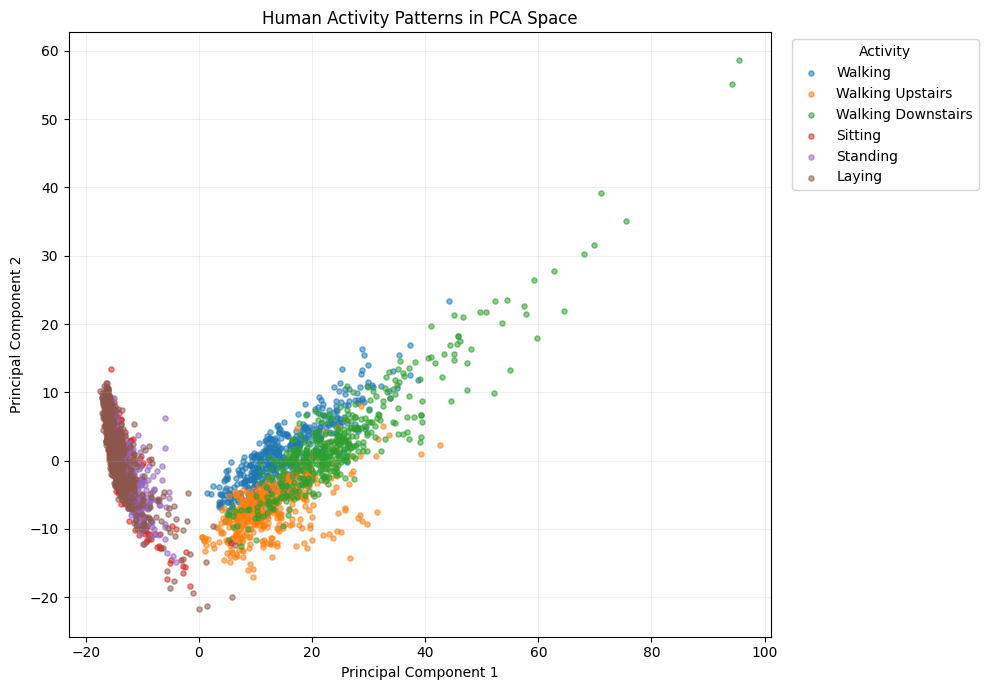

PCA ACTIVITY VISUALIZATION
Visualized observations: 3000
Principal components displayed: 2
Variance explained by PC1 and PC2: 57.3619%

PCA activity visualization verification passed.


In [9]:
# Create a reproducible sample for visualization.
rng = np.random.default_rng(RANDOM_STATE)

sample_size = min(3000, len(X_train_pca))
sample_indices = rng.choice(
    len(X_train_pca),
    size=sample_size,
    replace=False
)

# Extract the first two principal components.
pc1 = X_train_pca[sample_indices, 0]
pc2 = X_train_pca[sample_indices, 1]
sample_labels = y_train[sample_indices]

# Plot the six human activities.
plt.figure(figsize=(10, 7))

for activity_id, activity_name in activity_names.items():
    mask = sample_labels == activity_id

    plt.scatter(
        pc1[mask],
        pc2[mask],
        s=14,
        alpha=0.55,
        label=activity_name.replace("_", " ").title()
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Human Activity Patterns in PCA Space")
plt.legend(
    title="Activity",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Report the variance captured by the plotted components.
two_pc_variance = (
    pca_model.explained_variance_ratio_[:2].sum()
)

print("PCA ACTIVITY VISUALIZATION")
print("=" * 45)
print("Visualized observations:", sample_size)
print("Principal components displayed: 2")
print("Variance explained by PC1 and PC2:",
      f"{two_pc_variance:.4%}")

# Verify that all activities appear in the sample.
assert set(np.unique(sample_labels)) == set(range(1, 7))

print("\nPCA activity visualization verification passed.")

**Results:** The PCA visualization shows a broad separation between walking-related and stationary activities in the displayed projection. Walking, walking upstairs, and walking downstairs overlap with one another, as do sitting, standing, and laying. The first two principal components explain 57.3619% of the variance in the full standardized training partition of 7,352 sensor windows. The scatter plot displays a reproducible subset of 3,000 of those windows; the explained-variance percentage was not estimated from that plotting subset. These patterns suggest movement-related structure, which is evaluated quantitatively in the following clustering analysis.

## **Section 4:** K-Means Clustering

This section applies K-Means clustering to the PCA-transformed smartphone sensor features to investigate whether human activities form meaningful groups without using activity labels during model fitting. Different numbers of clusters will be evaluated using unsupervised clustering metrics, followed by comparisons with the recorded activity labels to examine movement-related and stationary patterns.

**Step 4.1:** Evaluate Candidate Numbers of Clusters

In [10]:
# Evaluate K-Means using the 63-component PCA training data.
cluster_range = range(2, 11)

kmeans_results = []

for k in cluster_range:
    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    labels = model.fit_predict(X_train_pca)

    # Use a reproducible sample for silhouette evaluation.
    silhouette = silhouette_score(
        X_train_pca,
        labels,
        sample_size=2000,
        random_state=RANDOM_STATE
    )

    kmeans_results.append({
        "Clusters": k,
        "Silhouette Score": silhouette,
        "Inertia": model.inertia_
    })

kmeans_summary = pd.DataFrame(kmeans_results)

print("K-MEANS CLUSTER EVALUATION")
print("=" * 55)
print(
    kmeans_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# Identify the highest silhouette score.
best_row = kmeans_summary.loc[
    kmeans_summary["Silhouette Score"].idxmax()
]

best_k = int(best_row["Clusters"])
best_silhouette = float(best_row["Silhouette Score"])

print("\nBEST CLUSTER COUNT")
print("=" * 55)
print("Selected clusters:", best_k)
print("Highest sampled silhouette score:",
      f"{best_silhouette:.4f}")

# Validate evaluation results.
assert len(kmeans_summary) == 9
assert kmeans_summary["Silhouette Score"].between(-1, 1).all()
assert (kmeans_summary["Inertia"] >= 0).all()
assert 2 <= best_k <= 10

print("\nK-Means cluster evaluation verification passed.")

K-MEANS CLUSTER EVALUATION
 Clusters  Silhouette Score      Inertia
        2            0.4415 1926016.0791
        3            0.3694 1671824.8716
        4            0.1956 1566560.6252
        5            0.1641 1465746.7113
        6            0.1403 1409648.5236
        7            0.1080 1368117.3917
        8            0.1145 1327307.9268
        9            0.1114 1287750.7797
       10            0.1075 1258552.7032

BEST CLUSTER COUNT
Selected clusters: 2
Highest sampled silhouette score: 0.4415

K-Means cluster evaluation verification passed.


**Results:** K-Means was evaluated using two through ten clusters in the 63-component PCA feature space. The two-cluster solution achieved the highest sampled silhouette score of 0.4415, followed by three clusters with a score of 0.3694. Silhouette scores generally decreased as the number of clusters increased, while inertia decreased across the evaluated configurations. Based on the sampled silhouette scores, two clusters were selected for further analysis. The relationship between these clusters and the recorded human activities will be examined in the next step.

**Step 4.2:** Analyze K-Means Cluster Composition

In [11]:
# Fit the selected K-Means model on PCA training features.
kmeans_model = KMeans(
    n_clusters=best_k,
    random_state=RANDOM_STATE,
    n_init=10
)

train_clusters = kmeans_model.fit_predict(X_train_pca)

# Compare clusters with recorded activity labels.
cluster_activity_counts = pd.crosstab(
    pd.Series(train_clusters, name="Cluster"),
    pd.Series(
        [activity_names[label] for label in y_train],
        name="Activity"
    )
)

cluster_activity_percent = (
    cluster_activity_counts.div(
        cluster_activity_counts.sum(axis=1),
        axis=0
    ) * 100
)

print("K-MEANS CLUSTER COMPOSITION")
print("=" * 65)
print("\nActivity counts by cluster:")
print(cluster_activity_counts.to_string())

print("\nActivity percentages within each cluster:")
print(cluster_activity_percent.round(2).to_string())

# Group activities into moving and stationary categories.
moving_activities = {1, 2, 3}

activity_groups = np.where(
    np.isin(y_train, list(moving_activities)),
    "Moving",
    "Stationary"
)

cluster_group_counts = pd.crosstab(
    pd.Series(train_clusters, name="Cluster"),
    pd.Series(activity_groups, name="Activity Group")
)

cluster_group_percent = (
    cluster_group_counts.div(
        cluster_group_counts.sum(axis=1),
        axis=0
    ) * 100
)

print("\nMOVING VS. STATIONARY CLUSTER COMPOSITION")
print("=" * 65)
print(cluster_group_counts.to_string())

print("\nPercentage composition:")
print(cluster_group_percent.round(2).to_string())

# Evaluate agreement with recorded activity groupings.
six_class_ari = adjusted_rand_score(
    y_train,
    train_clusters
)

binary_group_labels = np.isin(
    y_train,
    list(moving_activities)
).astype(int)

binary_group_ari = adjusted_rand_score(
    binary_group_labels,
    train_clusters
)

print("\nCLUSTER AGREEMENT METRICS")
print("=" * 65)
print("Adjusted Rand Index (six activities):",
      round(six_class_ari, 4))
print("Adjusted Rand Index (moving/stationary):",
      round(binary_group_ari, 4))

# Verify all observations are assigned.
assert len(train_clusters) == len(y_train)
assert len(np.unique(train_clusters)) == best_k
assert cluster_activity_counts.to_numpy().sum() == len(y_train)
assert cluster_group_counts.to_numpy().sum() == len(y_train)

print("\nK-Means cluster composition verification passed.")

K-MEANS CLUSTER COMPOSITION

Activity counts by cluster:
Activity  LAYING  SITTING  STANDING  WALKING  WALKING_DOWNSTAIRS  WALKING_UPSTAIRS
Cluster                                                                           
0           1396     1285      1374        0                   0                 8
1             11        1         0     1226                 986              1065

Activity percentages within each cluster:
Activity  LAYING  SITTING  STANDING  WALKING  WALKING_DOWNSTAIRS  WALKING_UPSTAIRS
Cluster                                                                           
0          34.36    31.63     33.82     0.00                0.00              0.20
1           0.33     0.03      0.00    37.28               29.98             32.38

MOVING VS. STATIONARY CLUSTER COMPOSITION
Activity Group  Moving  Stationary
Cluster                           
0                    8        4055
1                 3277          12

Percentage composition:
Activity Group  Moving  Stat

**Results:** The two-cluster K-Means solution demonstrated strong agreement with the broader activity categories. Cluster 0 contained 4,063 observations, of which 99.80% were stationary activities, while Cluster 1 contained 3,289 observations, of which 99.64% were moving activities. The Adjusted Rand Index was 0.9891 for moving versus stationary activities, compared with 0.3285 for the six individual activity classes. These findings indicate that K-Means identified a strong movement-related grouping in the training data without using activity labels during clustering.

**Step 4.3:** Visualize K-Means Clusters in PCA Space

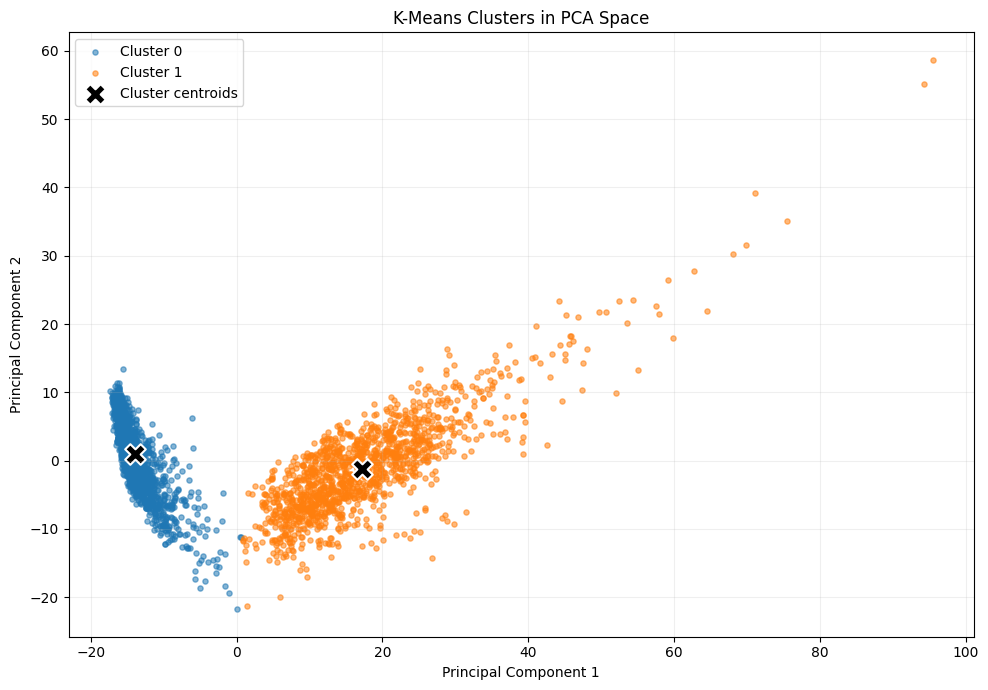

K-MEANS CLUSTER VISUALIZATION
Visualized observations: 3000
Number of clusters: 2
PCA components displayed: 2
Centroids displayed: 2

K-Means cluster visualization verification passed.


In [12]:
# Use the same reproducible sample from Step 3.4.
plot_indices = sample_indices

# Extract PCA coordinates and assigned clusters.
plot_pc1 = X_train_pca[plot_indices, 0]
plot_pc2 = X_train_pca[plot_indices, 1]
plot_clusters = train_clusters[plot_indices]

# Visualize the two K-Means clusters.
plt.figure(figsize=(10, 7))

for cluster_id in sorted(np.unique(train_clusters)):
    mask = plot_clusters == cluster_id

    plt.scatter(
        plot_pc1[mask],
        plot_pc2[mask],
        s=14,
        alpha=0.55,
        label=f"Cluster {cluster_id}"
    )

# Plot cluster centroids projected onto the first two PCs.
centroids = kmeans_model.cluster_centers_[:, :2]

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="X",
    s=220,
    c="black",
    edgecolors="white",
    linewidths=1.5,
    label="Cluster centroids"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters in PCA Space")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Verify visualization inputs.
assert len(plot_indices) == sample_size
assert len(plot_clusters) == sample_size
assert centroids.shape == (best_k, 2)

print("K-MEANS CLUSTER VISUALIZATION")
print("=" * 45)
print("Visualized observations:", len(plot_indices))
print("Number of clusters:", best_k)
print("PCA components displayed: 2")
print("Centroids displayed:", len(centroids))

print("\nK-Means cluster visualization verification passed.")

**Results:** The K-Means visualization shows two distinct activity clusters in the first two principal components. Cluster 0 is concentrated primarily on the left and corresponds predominantly to stationary activities, while Cluster 1 is concentrated on the right and corresponds predominantly to moving activities. Both cluster centroids are displayed, and the visualization includes 3,000 training observations. These findings visually support the strong moving-versus-stationary agreement identified in the previous analysis, although the original clustering was performed using all 63 principal components.

**Step 4.4:** Evaluate K-Means on Held-Out Participants

In [13]:
# Assign held-out observations to training-fitted K-Means clusters.
test_clusters = kmeans_model.predict(X_test_pca)

# Define moving and stationary activity groups.
moving_ids = {1, 2, 3}

test_activity_groups = np.where(
    np.isin(y_test, list(moving_ids)),
    "Moving",
    "Stationary"
)

# Examine cluster composition for held-out participants.
test_cluster_counts = pd.crosstab(
    pd.Series(test_clusters, name="Cluster"),
    pd.Series(test_activity_groups, name="Activity Group")
)

test_cluster_percent = (
    test_cluster_counts.div(
        test_cluster_counts.sum(axis=1),
        axis=0
    ) * 100
)

print("HELD-OUT PARTICIPANT CLUSTER COMPOSITION")
print("=" * 55)
print(test_cluster_counts.to_string())

print("\nPercentage composition:")
print(test_cluster_percent.round(2).to_string())

# Measure agreement without relying on arbitrary cluster IDs.
test_binary_labels = np.isin(
    y_test,
    list(moving_ids)
).astype(int)

test_binary_ari = adjusted_rand_score(
    test_binary_labels,
    test_clusters
)

test_six_class_ari = adjusted_rand_score(
    y_test,
    test_clusters
)

print("\nHELD-OUT CLUSTER AGREEMENT")
print("=" * 55)
print("Moving/stationary ARI:", round(test_binary_ari, 4))
print("Six-activity ARI:", round(test_six_class_ari, 4))

# Verify the original participant separation.
assert set(subject_train).isdisjoint(set(subject_test))
assert len(test_clusters) == len(y_test)
assert test_cluster_counts.to_numpy().sum() == len(y_test)
assert len(np.unique(test_clusters)) == best_k

print("\nHeld-out K-Means evaluation verification passed.")

HELD-OUT PARTICIPANT CLUSTER COMPOSITION
Activity Group  Moving  Stationary
Cluster                           
0                    1        1559
1                 1386           1

Percentage composition:
Activity Group  Moving  Stationary
Cluster                           
0                 0.06       99.94
1                99.93        0.07

HELD-OUT CLUSTER AGREEMENT
Moving/stationary ARI: 0.9973
Six-activity ARI: 0.3323

Held-out K-Means evaluation verification passed.


**Results:** The training-fitted K-Means model maintained strong moving-versus-stationary separation across the nine held-out participants. Cluster 0 contained 99.94% stationary observations, while Cluster 1 contained 99.93% moving observations. The moving-versus-stationary Adjusted Rand Index increased from 0.9891 during training to 0.9973 on the testing partition, while the six-activity ARI was 0.3323. Only two of the 2,947 testing observations differed from the predominant activity group of their assigned cluster. These findings indicate that the two-cluster structure generalizes well to unseen participants without refitting the clustering model.

## **Section 5:** Hierarchical Clustering

This section applies agglomerative hierarchical clustering to a reproducible sample of the PCA-transformed training data. Ward linkage is used to investigate the grouping structure of smartphone sensor observations. The resulting clusters will be evaluated against recorded activities and compared with K-Means using the same observations. Sampling is used to manage the computational demands of hierarchical clustering.

**Step 5.1:** Prepare a Representative Sample

In [14]:
# Select a reproducible, activity-stratified training sample.
HIERARCHICAL_SAMPLE_SIZE = 2000

sample_indices_hier, _ = train_test_split(
    np.arange(len(X_train_pca)),
    train_size=HIERARCHICAL_SAMPLE_SIZE,
    stratify=y_train,
    random_state=RANDOM_STATE
)

# Extract the corresponding PCA features and activity labels.
X_hier = X_train_pca[sample_indices_hier]
y_hier = y_train[sample_indices_hier]
subjects_hier = subject_train[sample_indices_hier]

# Summarize the sampled activity distribution.
hier_activity_counts = pd.Series(
    y_hier
).value_counts().sort_index()

hier_sample_summary = pd.DataFrame({
    "Activity": [
        activity_names[i] for i in hier_activity_counts.index
    ],
    "Sample count": hier_activity_counts.values,
    "Sample percentage": (
        hier_activity_counts.values / len(y_hier) * 100
    ).round(2)
})

print("HIERARCHICAL CLUSTERING SAMPLE")
print("=" * 50)
print("Sample observations:", len(X_hier))
print("PCA components:", X_hier.shape[1])
print("Participants represented:", len(np.unique(subjects_hier)))
print("Random state:", RANDOM_STATE)

print("\nSAMPLED ACTIVITY DISTRIBUTION")
print("=" * 50)
print(hier_sample_summary.to_string(index=False))

# Validate sampling.
assert X_hier.shape == (
    HIERARCHICAL_SAMPLE_SIZE,
    n_components_90
)
assert len(y_hier) == HIERARCHICAL_SAMPLE_SIZE
assert len(np.unique(sample_indices_hier)) == HIERARCHICAL_SAMPLE_SIZE
assert set(np.unique(y_hier)) == set(range(1, 7))
assert np.isfinite(X_hier).all()

print("\nHierarchical clustering sample verification passed.")

HIERARCHICAL CLUSTERING SAMPLE
Sample observations: 2000
PCA components: 63
Participants represented: 21
Random state: 42

SAMPLED ACTIVITY DISTRIBUTION
          Activity  Sample count  Sample percentage
           WALKING           333              16.65
  WALKING_UPSTAIRS           292              14.60
WALKING_DOWNSTAIRS           268              13.40
           SITTING           350              17.50
          STANDING           374              18.70
            LAYING           383              19.15

Hierarchical clustering sample verification passed.


**Results:** A reproducible, activity-stratified sample of 2,000 training observations was prepared for hierarchical clustering. The sample contains 63 PCA components per observation, represents all six activity classes, and includes data from all 21 training participants. The sampled activity proportions closely reflect the original training distribution. All verification checks passed, confirming that the sample is suitable for the planned hierarchical clustering analysis.

**Step 5.2:** Agglomerative Hierarchical Clustering

In [15]:
# Fit hierarchical clustering on the PCA training sample.
hierarchical_model = AgglomerativeClustering(
    n_clusters=best_k,
    linkage="ward"
)

hierarchical_labels = hierarchical_model.fit_predict(X_hier)

# Summarize the discovered clusters.
hier_cluster_counts = pd.Series(
    hierarchical_labels
).value_counts().sort_index()

print("AGGLOMERATIVE HIERARCHICAL CLUSTERING")
print("=" * 55)
print("Linkage method:", hierarchical_model.linkage)
print("Number of clusters:", hierarchical_model.n_clusters)
print("Observations clustered:", len(X_hier))
print("PCA components:", X_hier.shape[1])

print("\nHIERARCHICAL CLUSTER SIZES")
print("=" * 55)

for cluster_id, count in hier_cluster_counts.items():
    print(f"Cluster {cluster_id}: {count} observations")

# Evaluate cluster separation.
hier_silhouette = silhouette_score(
    X_hier,
    hierarchical_labels
)

# Evaluate agreement with six recorded activities.
hier_six_class_ari = adjusted_rand_score(
    y_hier,
    hierarchical_labels
)

# Evaluate agreement with moving/stationary groups.
hier_binary_labels = np.isin(
    y_hier,
    [1, 2, 3]
).astype(int)

hier_binary_ari = adjusted_rand_score(
    hier_binary_labels,
    hierarchical_labels
)

print("\nHIERARCHICAL CLUSTER EVALUATION")
print("=" * 55)
print("Silhouette score:", round(hier_silhouette, 4))
print("Six-activity ARI:", round(hier_six_class_ari, 4))
print("Moving/stationary ARI:", round(hier_binary_ari, 4))

# Verify clustering results.
assert len(hierarchical_labels) == len(X_hier)
assert len(np.unique(hierarchical_labels)) == best_k
assert hier_cluster_counts.sum() == len(X_hier)
assert -1 <= hier_silhouette <= 1
assert -1 <= hier_binary_ari <= 1
assert -1 <= hier_six_class_ari <= 1

print("\nHierarchical clustering verification passed.")

AGGLOMERATIVE HIERARCHICAL CLUSTERING
Linkage method: ward
Number of clusters: 2
Observations clustered: 2000
PCA components: 63

HIERARCHICAL CLUSTER SIZES
Cluster 0: 893 observations
Cluster 1: 1107 observations

HIERARCHICAL CLUSTER EVALUATION
Silhouette score: 0.4366
Six-activity ARI: 0.3316
Moving/stationary ARI: 1.0

Hierarchical clustering verification passed.


**Results:** Agglomerative hierarchical clustering with Ward linkage divided the 2,000 sampled training observations into two clusters containing 893 and 1,107 observations. The silhouette score was 0.4366, indicating measurable separation in the 63-component PCA feature space. The moving-versus-stationary Adjusted Rand Index reached 1.0000, demonstrating perfect agreement with the broader activity categories within this sample. The six-activity ARI was 0.3316, reflecting the limited ability of two clusters to represent six individual activities.

**Step 5.3:** Compare Hierarchical Clustering with K-Means

In [16]:
# Fit K-Means independently on the same hierarchical sample.
kmeans_sample_model = KMeans(
    n_clusters=best_k,
    random_state=RANDOM_STATE,
    n_init=10
)

kmeans_sample_labels = kmeans_sample_model.fit_predict(X_hier)

# Evaluate K-Means on the identical sample.
kmeans_sample_silhouette = silhouette_score(
    X_hier,
    kmeans_sample_labels
)

kmeans_sample_six_ari = adjusted_rand_score(
    y_hier,
    kmeans_sample_labels
)

kmeans_sample_binary_ari = adjusted_rand_score(
    hier_binary_labels,
    kmeans_sample_labels
)

# Measure agreement between the two clustering algorithms.
algorithm_agreement_ari = adjusted_rand_score(
    hierarchical_labels,
    kmeans_sample_labels
)

# Construct a direct comparison.
clustering_comparison = pd.DataFrame({
    "Algorithm": [
        "K-Means",
        "Hierarchical (Ward)"
    ],
    "Silhouette Score": [
        kmeans_sample_silhouette,
        hier_silhouette
    ],
    "Six-Activity ARI": [
        kmeans_sample_six_ari,
        hier_six_class_ari
    ],
    "Moving/Stationary ARI": [
        kmeans_sample_binary_ari,
        hier_binary_ari
    ]
})

print("CLUSTERING ALGORITHM COMPARISON")
print("=" * 75)
print(
    clustering_comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nAGREEMENT BETWEEN ALGORITHMS")
print("=" * 45)
print(
    "Adjusted Rand Index:",
    round(algorithm_agreement_ari, 4)
)

# Verify comparison consistency.
assert len(kmeans_sample_labels) == len(hierarchical_labels)
assert len(np.unique(kmeans_sample_labels)) == best_k
assert clustering_comparison.shape == (2, 4)
assert clustering_comparison.iloc[1]["Silhouette Score"] == hier_silhouette
assert -1 <= algorithm_agreement_ari <= 1

print("\nClustering algorithm comparison verification passed.")

CLUSTERING ALGORITHM COMPARISON
          Algorithm  Silhouette Score  Six-Activity ARI  Moving/Stationary ARI
            K-Means            0.4369            0.3276                 0.9880
Hierarchical (Ward)            0.4366            0.3316                 1.0000

AGREEMENT BETWEEN ALGORITHMS
Adjusted Rand Index: 0.988

Clustering algorithm comparison verification passed.


**Results:** On the same 2,000-observation training sample, Ward hierarchical clustering achieved a silhouette score of 0.4366 and a moving-versus-stationary Adjusted Rand Index (ARI) of 1.0000. K-Means achieved a slightly higher silhouette score of 0.4369 and a moving-versus-stationary ARI of 0.9880. The ARI between the two clustering solutions was also 0.9880 because Ward's clustering exactly matched the moving-versus-stationary grouping on this sample. Both methods identified similar broad activity patterns, although neither clustering solution was designed to distinguish all six individual activities.

**Step 5.4:** Visualize Hierarchical Clustering Structure

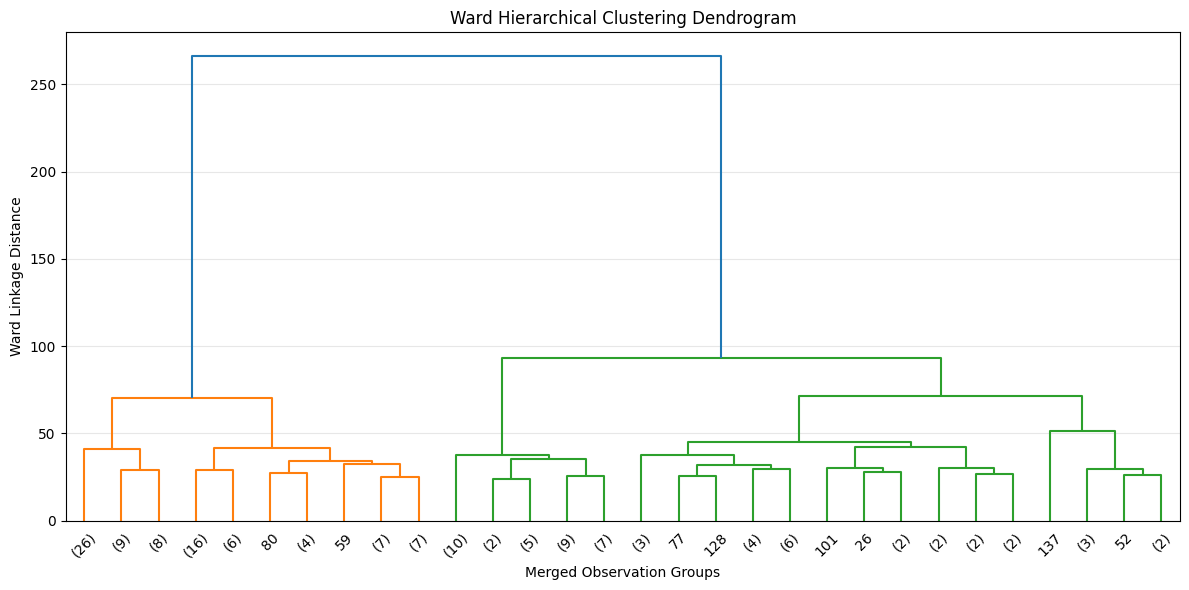

HIERARCHICAL DENDROGRAM VERIFICATION
Observations used: 150
Linkage method: Ward
Linkage merges: 149

Hierarchical dendrogram verification passed.


In [17]:
# Select a smaller reproducible subset for dendrogram visualization.
DENDROGRAM_SAMPLE_SIZE = 150

rng_dendrogram = np.random.default_rng(RANDOM_STATE)

dendrogram_indices = rng_dendrogram.choice(
    len(X_hier),
    size=DENDROGRAM_SAMPLE_SIZE,
    replace=False
)

X_dendrogram = X_hier[dendrogram_indices]

# Compute Ward hierarchical linkage.
linkage_matrix = linkage(
    X_dendrogram,
    method="ward",
    metric="euclidean"
)

# Visualize the hierarchical merging structure.
plt.figure(figsize=(12, 6))

dendrogram(
    linkage_matrix,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True,
    leaf_rotation=45
)

plt.title("Ward Hierarchical Clustering Dendrogram")
plt.xlabel("Merged Observation Groups")
plt.ylabel("Ward Linkage Distance")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Verify linkage structure.
assert linkage_matrix.shape == (
    DENDROGRAM_SAMPLE_SIZE - 1,
    4
)

assert np.isfinite(linkage_matrix).all()
assert np.all(np.diff(linkage_matrix[:, 2]) >= -1e-10)

print("HIERARCHICAL DENDROGRAM VERIFICATION")
print("=" * 45)
print("Observations used:", DENDROGRAM_SAMPLE_SIZE)
print("Linkage method: Ward")
print("Linkage merges:", len(linkage_matrix))

print("\nHierarchical dendrogram verification passed.")

**Results:** The Ward hierarchical clustering dendrogram illustrates the merging structure of 150 sampled training observations. Two major branches are visible, with the final merge occurring at a substantially greater linkage distance than the preceding merges. This pattern suggests a pronounced two-group structure within the sampled PCA features. The visualization supports the earlier hierarchical clustering analysis, although activity labels are required to determine how the branches correspond to recorded human activities.

## **Section 6:** Cluster-Distance Classification

This section investigates whether distances to K-Means cluster centers provide useful additional information for supervised human activity classification. Logistic Regression will be used to compare a baseline model trained on PCA features with an enhanced model that incorporates cluster-distance features. Participant-aware validation will be used to evaluate whether the additional features improve performance while preventing information leakage between training and validation participants.

**Step 6.1:** Generate Cluster-Distance Features

In [18]:
# Generate distances to the training-fitted K-Means centroids.
train_cluster_distances = kmeans_model.transform(X_train_pca)
test_cluster_distances = kmeans_model.transform(X_test_pca)

# Combine PCA and cluster-distance features.
X_train_enhanced = np.column_stack([
    X_train_pca,
    train_cluster_distances
])

X_test_enhanced = np.column_stack([
    X_test_pca,
    test_cluster_distances
])

print("CLUSTER-DISTANCE FEATURE GENERATION")
print("=" * 55)
print("Number of K-Means clusters:", best_k)
print("Original PCA features:", X_train_pca.shape[1])
print("Additional distance features:", train_cluster_distances.shape[1])

print("\nFEATURE MATRIX DIMENSIONS")
print("=" * 55)
print("Training distance shape:", train_cluster_distances.shape)
print("Testing distance shape:", test_cluster_distances.shape)
print("Enhanced training shape:", X_train_enhanced.shape)
print("Enhanced testing shape:", X_test_enhanced.shape)

print("\nTRAINING DISTANCE SUMMARY")
print("=" * 55)

distance_summary = pd.DataFrame(
    train_cluster_distances,
    columns=[
        f"Distance to Cluster {i}"
        for i in range(best_k)
    ]
)

print(distance_summary.describe().round(4).to_string())

# Verify feature dimensions and valid distances.
assert train_cluster_distances.shape == (7352, best_k)
assert test_cluster_distances.shape == (2947, best_k)

assert X_train_enhanced.shape == (
    len(X_train),
    n_components_90 + best_k
)

assert X_test_enhanced.shape == (
    len(X_test),
    n_components_90 + best_k
)

assert np.isfinite(X_train_enhanced).all()
assert np.isfinite(X_test_enhanced).all()
assert np.all(train_cluster_distances >= 0)
assert np.all(test_cluster_distances >= 0)

# Confirm assigned clusters correspond to the nearest centroids.
assert np.array_equal(
    np.argmin(train_cluster_distances, axis=1),
    train_clusters
)

print("\nCluster-distance feature verification passed.")

CLUSTER-DISTANCE FEATURE GENERATION
Number of K-Means clusters: 2
Original PCA features: 63
Additional distance features: 2

FEATURE MATRIX DIMENSIONS
Training distance shape: (7352, 2)
Testing distance shape: (2947, 2)
Enhanced training shape: (7352, 65)
Enhanced testing shape: (2947, 65)

TRAINING DISTANCE SUMMARY
       Distance to Cluster 0  Distance to Cluster 1
count              7352.0000              7352.0000
mean                 22.5125                26.7533
std                  13.9752                 9.4837
min                   5.6458                 9.2693
25%                  10.8542                16.5094
50%                  16.0171                31.7326
75%                  32.1112                34.2396
max                 150.3480               131.2653

Cluster-distance feature verification passed.


**Results:** Two cluster-distance features were successfully generated using the K-Means model fitted on the training partition. Each feature represents an observation's Euclidean distance to one of the two cluster centers. Combining these distances with the 63 PCA components produced enhanced feature matrices containing 65 features for 7,352 training observations and 2,947 testing observations. All distance and dimensionality checks passed. The effectiveness of these additional features will be assessed through classification experiments.

**Step 6.2:** Compare Baseline and Cluster-Distance Classification

In [19]:
# Define identical Logistic Regression configurations.
baseline_classifier = LogisticRegression(
    C=1.0,
    max_iter=2000,
    random_state=RANDOM_STATE
)

enhanced_classifier = LogisticRegression(
    C=1.0,
    max_iter=2000,
    random_state=RANDOM_STATE
)

# Train both models using the original training participants.
baseline_classifier.fit(X_train_pca, y_train)
enhanced_classifier.fit(X_train_enhanced, y_train)

# Evaluate on the original held-out participants.
baseline_predictions = baseline_classifier.predict(X_test_pca)
enhanced_predictions = enhanced_classifier.predict(X_test_enhanced)

# Calculate classification metrics.
baseline_accuracy = accuracy_score(
    y_test,
    baseline_predictions
)

enhanced_accuracy = accuracy_score(
    y_test,
    enhanced_predictions
)

baseline_macro_f1 = f1_score(
    y_test,
    baseline_predictions,
    average="macro"
)

enhanced_macro_f1 = f1_score(
    y_test,
    enhanced_predictions,
    average="macro"
)

# Summarize the comparison.
classification_comparison = pd.DataFrame({
    "Model": [
        "PCA Baseline",
        "PCA + Cluster Distances"
    ],
    "Features": [
        X_train_pca.shape[1],
        X_train_enhanced.shape[1]
    ],
    "Accuracy": [
        baseline_accuracy,
        enhanced_accuracy
    ],
    "Macro F1": [
        baseline_macro_f1,
        enhanced_macro_f1
    ]
})

print("CLUSTER-DISTANCE CLASSIFICATION COMPARISON")
print("=" * 70)
print(
    classification_comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nPERFORMANCE DIFFERENCES")
print("=" * 45)
print(
    "Accuracy difference:",
    f"{enhanced_accuracy - baseline_accuracy:+.4f}"
)
print(
    "Macro F1 difference:",
    f"{enhanced_macro_f1 - baseline_macro_f1:+.4f}"
)

# Verify participant separation and classification outputs.
assert set(subject_train).isdisjoint(set(subject_test))
assert len(baseline_predictions) == len(y_test)
assert len(enhanced_predictions) == len(y_test)
assert set(np.unique(baseline_predictions)).issubset(set(range(1, 7)))
assert set(np.unique(enhanced_predictions)).issubset(set(range(1, 7)))

for metric in [
    baseline_accuracy,
    enhanced_accuracy,
    baseline_macro_f1,
    enhanced_macro_f1
]:
    assert 0 <= metric <= 1

print("\nClassification comparison verification passed.")

CLUSTER-DISTANCE CLASSIFICATION COMPARISON
                  Model  Features  Accuracy  Macro F1
           PCA Baseline        63    0.9230    0.9220
PCA + Cluster Distances        65    0.9226    0.9219

PERFORMANCE DIFFERENCES
Accuracy difference: -0.0003
Macro F1 difference: -0.0001

Classification comparison verification passed.


**Results:** On the held-out testing partition, the PCA baseline achieved an accuracy of 0.9230 and a macro F1-score of 0.9220. Adding two K-Means cluster-distance features produced an accuracy of 0.9226 and a macro F1-score of 0.9219. The accuracy difference corresponds to one additional misclassified observation among the 2,947 testing observations. These negligible differences indicate that cluster-distance features did not meaningfully improve six-activity classification performance under the evaluated configuration.

**Step 6.3:** Participant-Aware Cross-Validation

In [20]:
class ClusterDistanceFeatures(BaseEstimator, TransformerMixin):
    """Append K-Means centroid distances to PCA features."""

    def __init__(self, n_clusters=2, random_state=42):
        self.n_clusters = n_clusters
        self.random_state = random_state

    def fit(self, X, y=None):
        self.kmeans_ = KMeans(
            n_clusters=self.n_clusters,
            n_init=10,
            random_state=self.random_state
        )
        self.kmeans_.fit(X)
        return self

    def transform(self, X):
        distances = self.kmeans_.transform(X)
        return np.column_stack([X, distances])


# Define preprocessing and classification pipelines.
baseline_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.90, svd_solver="full")),
    ("classifier", LogisticRegression(
        C=1.0,
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

enhanced_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.90, svd_solver="full")),
    ("cluster_features", ClusterDistanceFeatures(
        n_clusters=best_k,
        random_state=RANDOM_STATE
    )),
    ("classifier", LogisticRegression(
        C=1.0,
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

# Construct participant-aware validation folds.
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_results = []

for fold_number, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train, groups=subject_train),
    start=1
):
    # Verify participants do not overlap.
    train_subjects = set(subject_train[train_idx])
    val_subjects = set(subject_train[val_idx])

    assert train_subjects.isdisjoint(val_subjects)

    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train[train_idx]
    y_fold_val = y_train[val_idx]

    # Fit separate pipelines on fold-training data only.
    baseline_fold = clone(baseline_pipeline)
    enhanced_fold = clone(enhanced_pipeline)

    baseline_fold.fit(X_fold_train, y_fold_train)
    enhanced_fold.fit(X_fold_train, y_fold_train)

    baseline_val_pred = baseline_fold.predict(X_fold_val)
    enhanced_val_pred = enhanced_fold.predict(X_fold_val)

    cv_results.append({
        "Fold": fold_number,
        "Validation Samples": len(val_idx),
        "Baseline Macro F1": f1_score(
            y_fold_val,
            baseline_val_pred,
            average="macro",
            zero_division=0
        ),
        "Enhanced Macro F1": f1_score(
            y_fold_val,
            enhanced_val_pred,
            average="macro",
            zero_division=0
        )
    })

cv_summary = pd.DataFrame(cv_results)

cv_summary["F1 Difference"] = (
    cv_summary["Enhanced Macro F1"]
    - cv_summary["Baseline Macro F1"]
)

print("PARTICIPANT-AWARE CROSS-VALIDATION")
print("=" * 75)
print(
    cv_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nCROSS-VALIDATION SUMMARY")
print("=" * 45)
print("Baseline mean macro F1:",
      round(cv_summary["Baseline Macro F1"].mean(), 4))
print("Enhanced mean macro F1:",
      round(cv_summary["Enhanced Macro F1"].mean(), 4))
print("Mean F1 difference:",
      round(cv_summary["F1 Difference"].mean(), 4))

assert len(cv_summary) == 5
assert cv_summary["Validation Samples"].sum() == len(X_train)

print("\nParticipant-aware cross-validation verification passed.")

PARTICIPANT-AWARE CROSS-VALIDATION
 Fold  Validation Samples  Baseline Macro F1  Enhanced Macro F1  F1 Difference
    1                1528             0.8977             0.8985         0.0008
    2                1387             0.8994             0.8989        -0.0005
    3                1633             0.9089             0.9109         0.0019
    4                1422             0.8291             0.8316         0.0025
    5                1382             0.9600             0.9609         0.0009

CROSS-VALIDATION SUMMARY
Baseline mean macro F1: 0.899
Enhanced mean macro F1: 0.9002
Mean F1 difference: 0.0011

Participant-aware cross-validation verification passed.


**Results:** In the saved Colab execution, five-fold participant-aware cross-validation produced mean macro F1-scores of 0.8990 for the PCA baseline and 0.9002 for the model with cluster-distance features. The enhanced model performed better in four of five folds, with a mean paired improvement of approximately 0.0011 calculated before rounding. StandardScaler, PCA using the 90% variance rule, K-Means, and Logistic Regression were fitted using each fold's training data only. The PCA component count was therefore determined within each fold rather than fixed at the full-training count of 63. The number of clusters was held at the value selected during the earlier training-set exploration, so these scores evaluate that chosen configuration rather than a nested reselection of the complete modeling procedure. The gain was small and varied across folds; it does not establish a statistically reliable classification improvement.

## **Section 7:** Final Evaluation and Validation

This section consolidates the results from PCA, K-Means, hierarchical clustering, and cluster-distance classification. The analysis verifies that the reported metrics correspond to the correct dataset partitions, that participant separation was maintained, and that the numerical conclusions are consistent with the completed experiments.

**Step 7.1:** Consolidate and Verify Experimental Results

In [21]:
# Consolidate the key experimental results.
final_results = pd.DataFrame({
    "Experiment": [
        "PCA variance retention",
        "K-Means training (moving/stationary)",
        "K-Means held-out (moving/stationary)",
        "Hierarchical sample (moving/stationary)",
        "K-Means sample (moving/stationary)",
        "Baseline classification (test)",
        "Enhanced classification (test)",
        "Baseline classification (CV)",
        "Enhanced classification (CV)"
    ],
    "Metric": [
        "Explained variance",
        "Adjusted Rand Index",
        "Adjusted Rand Index",
        "Adjusted Rand Index",
        "Adjusted Rand Index",
        "Macro F1",
        "Macro F1",
        "Mean macro F1",
        "Mean macro F1"
    ],
    "Value": [
        variance_retained,
        binary_group_ari,
        test_binary_ari,
        hier_binary_ari,
        kmeans_sample_binary_ari,
        baseline_macro_f1,
        enhanced_macro_f1,
        cv_summary["Baseline Macro F1"].mean(),
        cv_summary["Enhanced Macro F1"].mean()
    ]
})

print("FINAL EXPERIMENTAL RESULTS")
print("=" * 80)
print(
    final_results.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nFINAL DATA AND LEAKAGE CHECKS")
print("=" * 55)

# Confirm original participant separation.
participant_overlap = len(
    set(subject_train) & set(subject_test)
)

print("Participant overlap:", participant_overlap)
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("PCA components:", n_components_90)
print("Enhanced feature count:", X_train_enhanced.shape[1])
print("Cross-validation folds:", len(cv_summary))

# Confirm the original training/test separation.
assert participant_overlap == 0

# Confirm the PCA transformation used training observations only.
assert pca_model.n_samples_ == len(X_train)

# Confirm clustering and feature dimensions.
assert len(train_clusters) == len(X_train)
assert len(test_clusters) == len(X_test)
assert X_train_enhanced.shape[1] == n_components_90 + best_k

# Confirm all final metrics are finite and within their valid ranges.
assert np.isfinite(final_results["Value"]).all()

ari_mask = final_results["Metric"] == "Adjusted Rand Index"
assert final_results.loc[ari_mask, "Value"].between(-1, 1).all()
assert final_results.loc[~ari_mask, "Value"].between(0, 1).all()

# Confirm all training observations were validated once.
assert cv_summary["Validation Samples"].sum() == len(X_train)

print("\nAll final consistency checks passed.")

FINAL EXPERIMENTAL RESULTS
                             Experiment              Metric  Value
                 PCA variance retention  Explained variance 0.9005
   K-Means training (moving/stationary) Adjusted Rand Index 0.9891
   K-Means held-out (moving/stationary) Adjusted Rand Index 0.9973
Hierarchical sample (moving/stationary) Adjusted Rand Index 1.0000
     K-Means sample (moving/stationary) Adjusted Rand Index 0.9880
         Baseline classification (test)            Macro F1 0.9220
         Enhanced classification (test)            Macro F1 0.9219
           Baseline classification (CV)       Mean macro F1 0.8990
           Enhanced classification (CV)       Mean macro F1 0.9002

FINAL DATA AND LEAKAGE CHECKS
Participant overlap: 0
Training observations: 7352
Testing observations: 2947
PCA components: 63
Enhanced feature count: 65
Cross-validation folds: 5

All final consistency checks passed.


**Results:** The final verification confirmed that PCA retained 90.0535% of the training variance using 63 components. K-Means achieved moving-versus-stationary ARI values of 0.9891 on training data and 0.9973 on held-out testing data. Hierarchical clustering achieved an ARI of 1.0000 on its 2,000-observation sample, compared with 0.9880 for K-Means on the same sample. Adding cluster-distance features produced only minor changes in six-activity classification performance, with a testing macro F1-score of 0.9219 compared with 0.9220 for the baseline. All consolidated metrics and dataset consistency checks passed.

## **Section 8:** Conclusions and Integration

This section summarizes the principal findings of the PCA and clustering analyses, evaluates the limitations of the experiments, and identifies results that can be incorporated into the team's Human Activity Recognition project.

**Step 8.1:** Summarize Findings and Limitations

In [22]:
# Summarize the completed PCA and clustering experiments.
clustering_summary = pd.DataFrame({
    "Research Question": [
        "How much dimensionality can PCA reduce?",
        "Can K-Means separate moving and stationary activities?",
        "Does K-Means generalize to unseen participants?",
        "Does hierarchical clustering find similar groups?",
        "Do cluster-distance features improve classification?"
    ],
    "Finding": [
        f"{n_components_90} components retain {variance_retained:.2%} variance",
        f"Training moving/stationary ARI = {binary_group_ari:.4f}",
        f"Held-out moving/stationary ARI = {test_binary_ari:.4f}",
        f"Hierarchical ARI = {hier_binary_ari:.4f} on {len(X_hier)} sampled observations",
        (
            "Test macro F1 difference = "
            f"{enhanced_macro_f1 - baseline_macro_f1:+.4f}"
        )
    ]
})

print("PCA AND CLUSTERING: FINAL RESEARCH SUMMARY")
print("=" * 90)
print(clustering_summary.to_string(index=False))

print("\nLIMITATIONS")
print("=" * 90)
print("1. PCA variance retention does not guarantee optimal clustering.")
print("2. Hierarchical clustering was evaluated on a training subset.")
print("3. Two clusters primarily represent broad movement categories, not all six activities.")
print("4. Cluster-distance classification was tested with Logistic Regression.")
print("5. Cross-validation improvements were small and varied across folds.")

print("\nANALYSIS STATUS")
print("=" * 90)
print("PCA analysis: Completed")
print("K-Means clustering: Completed")
print("Hierarchical clustering: Completed")
print("Cluster-distance experiment: Completed")
print("Participant-aware validation: Completed")

# Verify the summary includes all five research questions.
assert len(clustering_summary) == 5
assert clustering_summary["Finding"].notna().all()

print("\nPCA and clustering summary verification passed.")

PCA AND CLUSTERING: FINAL RESEARCH SUMMARY
                                     Research Question                                                Finding
               How much dimensionality can PCA reduce?                   63 components retain 90.05% variance
Can K-Means separate moving and stationary activities?                Training moving/stationary ARI = 0.9891
       Does K-Means generalize to unseen participants?                Held-out moving/stationary ARI = 0.9973
     Does hierarchical clustering find similar groups? Hierarchical ARI = 1.0000 on 2000 sampled observations
  Do cluster-distance features improve classification?                     Test macro F1 difference = -0.0001

LIMITATIONS
1. PCA variance retention does not guarantee optimal clustering.
2. Hierarchical clustering was evaluated on a training subset.
3. Two clusters primarily represent broad movement categories, not all six activities.
4. Cluster-distance classification was tested with Logistic Regressio

**Results:** PCA reduced 561 sensor features to 63 components while retaining approximately 90.05% of the training variance. K-Means and Ward hierarchical clustering identified strong moving-versus-stationary activity groupings. The training-fitted K-Means model maintained high agreement on the nine held-out participants, while Ward achieved an ARI of 1.0000 on its 2,000-observation training sample. Adding cluster-distance features produced a small mean cross-validation improvement of approximately 0.0011, but held-out macro F1 decreased slightly from 0.9220 to 0.9219. These results do not demonstrate a reliable classification improvement from cluster-distance features.

**Limitations:** The dataset contains overlapping sensor windows from 30 participants, so observations from the same participant are not independent. Hierarchical clustering was evaluated on a sampled training subset, and cross-validation used a previously selected cluster count. Generalization beyond the evaluated participants and data collection conditions remains uncertain. Small classification differences may be sensitive to numerical environments, and statistical significance was not established.